# Medical Transcription NLP Classification
### Phase 1 → Preprocessing | Phase 2 → Entities | Phase 3 → Negation | Phase 4 → Classification

In [1]:
!pip install spacy imbalanced-learn scikit-learn seaborn matplotlib -q
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 95.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# Kaggle credentials & dataset download
from google.colab import files
files.upload()

Saving kaggle (1).json to kaggle (1).json


{'kaggle (1).json': b'{"username":"rj041103","key":"19e5d308d8e4c160ce170d3e0a7a1771"}'}

In [3]:
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d tboyle10/medicaltranscriptions -q
!unzip -q medicaltranscriptions.zip

cp: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions
License(s): CC0-1.0


# Phase 1: Data Loading & Preprocessing

In [15]:
import pandas as pd
import numpy as np
import re, string, warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("mtsamples.csv")
df['medical_specialty'] = df['medical_specialty'].fillna('').astype(str).str.strip()
df = df.dropna(subset=["transcription"]).reset_index(drop=True)

print("Full dataset shape:", df.shape)
print("\nTop 10 specialties:")
print(df['medical_specialty'].value_counts().head(10))

Full dataset shape: (4966, 6)

Top 10 specialties:
medical_specialty
Surgery                          1088
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Name: count, dtype: int64


In [42]:
SELECTED_SPECIALTIES = [
    "Gastroenterology",
    "Cardiovascular / Pulmonary",
    "Orthopedic",
    "Neurology"

]

df = df[df["medical_specialty"].isin(SELECTED_SPECIALTIES)].reset_index(drop=True)
print("Filtered dataset shape:", df.shape)
print("\nClass distribution:")
print(df["medical_specialty"].value_counts())

Filtered dataset shape: (1173, 10)

Class distribution:
medical_specialty
Cardiovascular / Pulmonary    371
Orthopedic                    355
Gastroenterology              224
Neurology                     223
Name: count, dtype: int64


In [17]:
import spacy
nlp = spacy.load("en_core_web_sm")
print("spaCy model loaded.")

spaCy model loaded.


## Abbreviation Dictionary

In [18]:
abbrev_dict = {
    "pt":   "patient",
    "hx":   "history",
    "dx":   "diagnosis",
    "fx":   "fracture",
    "sx":   "symptom",
    "bp":   "blood pressure",
    "htn":  "hypertension",
    "dm":   "diabetes",
    "sob":  "shortness of breath",
    "gi":   "gastrointestinal",
    "gerd": "gastroesophageal reflux disease",
    "ibd":  "inflammatory bowel disease",
    "egd":  "esophagogastroduodenoscopy",
    "ekg":  "electrocardiogram",
    "mi":   "myocardial infarction",
    "chf":  "congestive heart failure",
    "copd": "chronic obstructive pulmonary disease",
    "tia":  "transient ischemic attack",
    "cva":  "cerebrovascular accident",
    "ms":   "multiple sclerosis",
    "rom":  "range of motion",
    "oa":   "osteoarthritis",
    "ra":   "rheumatoid arthritis",
}

def expand_abbreviations(text):
    words = text.split()
    expanded = []
    for word in words:
        clean = word.strip(string.punctuation)
        expanded.append(abbrev_dict.get(clean, word))
    return " ".join(expanded)

In [50]:
example_text = "pt hx of dm"
expanded_text = expand_abbreviations(example_text)

print(f'"{example_text}"')
print(f'→ "{expanded_text}"')

"pt hx of dm"
→ "patient history of diabetes"


## Header Removal & Preprocessing Pipeline

In [19]:
def remove_headers(text):
    text = re.sub(r"Sample Name:.*?\n", "", text, flags=re.IGNORECASE)
    text = re.sub(r"ID:.*?\n",          "", text, flags=re.IGNORECASE)
    text = re.sub(r"Date:.*?\n",         "", text, flags=re.IGNORECASE)
    text = re.sub(r"Dictated By:.*?\n",  "", text, flags=re.IGNORECASE)
    return text

# FIX 2: Correct pipeline order
#   remove_headers → expand_abbreviations → lowercase → spaCy (lemmatize/filter)
def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    text = remove_headers(text)             # 1. strip boilerplate headers
    text = expand_abbreviations(text.lower())  # 2. lowercase then expand abbrevs
    text = re.sub(r'\d+', '', text)          # 3. remove numbers
    doc  = nlp(text)                         # 4. spaCy: lemmatize + filter
    tokens = [
        token.lemma_ for token in doc
        if not token.is_stop and not token.is_punct and token.lemma_.isalpha()
    ]
    return " ".join(tokens)

In [20]:
df["clean_text"] = df["transcription"].apply(preprocess_text)

# Sanity check
print("Shape:", df.shape)
print("Nulls in clean_text:", df["clean_text"].isnull().sum())
print("Empty strings:      ", (df["clean_text"].str.strip() == "").sum())
print("\nSample before → after:")
print("BEFORE:", df["transcription"].iloc[0][:200])
print("AFTER: ", df["clean_text"].iloc[0][:200])

Shape: (1173, 7)
Nulls in clean_text: 0
Empty strings:       0

Sample before → after:
BEFORE: 2-D M-MODE: , ,1.  Left atrial enlargement with left atrial diameter of 4.7 cm.,2.  Normal size right and left ventricle.,3.  Normal LV systolic function with left ventricular ejection fraction of 51%
AFTER:  m mode leave atrial enlargement leave atrial diameter cm normal size right left ventricle normal lv systolic function leave ventricular ejection fraction normal lv diastolic function pericardial effus


# Phase 2: Entity Extraction

In [21]:
def extract_entities(text):
    doc = nlp(text)
    nouns      = [t.lemma_ for t in doc if t.pos_ == "NOUN"]
    adjectives = [t.lemma_ for t in doc if t.pos_ == "ADJ"]
    return nouns, adjectives

df["nouns"], df["adjectives"] = zip(*df["clean_text"].apply(extract_entities))
df[["medical_specialty", "nouns", "adjectives"]].head(3)

,medical_specialty,nouns,adjectives
0,Cardiovascular / Pulmonary,"[mode, enlargement, diameter, size, ventricle,...","[atrial, atrial, normal, normal, systolic, ven..."
1,Cardiovascular / Pulmonary,"[cavity, size, wall, wall, motion, function, e...","[ventricular, normal, ventricular, systolic, h..."
2,Cardiovascular / Pulmonary,"[echocardiogram, view, heart, vessel, vessel, ...","[multiple, great, normal, intracardiac, great,..."


In [22]:
# Generic clinical terms that appear in every specialty — filter before analysis
medical_stopwords = {
    "patient", "place", "procedure", "note", "room", "time",
    "study", "report", "exam", "history", "assessment", "plan",
    "finding", "result", "follow", "year", "day", "week",
    "discharge", "admission", "record", "documentation", "review"
}

from collections import Counter

def top_nouns_by_specialty(specialty, top_n=10):
    subset = df[df["medical_specialty"] == specialty]
    all_nouns = [
        n for noun_list in subset["nouns"]
        for n in noun_list
        if n not in medical_stopwords and len(n) > 2
    ]
    return Counter(all_nouns).most_common(top_n)

print("=== Top Nouns by Specialty ===")
for spec in SELECTED_SPECIALTIES:
    print(f"\n{spec}:")
    for term, count in top_nouns_by_specialty(spec, 5):
        print(f"  {term}: {count}")

=== Top Nouns by Specialty ===

Gastroenterology:
  colon: 237
  diagnosis: 219
  pain: 200
  stomach: 149
  blood: 148

Radiology :

Cardiovascular / Pulmonary:
  artery: 1171
  pressure: 442
  disease: 424
  heart: 406
  chest: 378

Orthopedic:
  pain: 751
  incision: 491
  knee: 455
  diagnosis: 430
  position: 428

Neurology:
  pain: 231
  extremity: 225
  weakness: 162
  brain: 152
  blood: 137


In [52]:
import pandas as pd

vocab_data = {}
for spec in SELECTED_SPECIALTIES:
    top_terms = top_nouns_by_specialty(spec, 5)
    # Format as 'term (count)' for the table
    vocab_data[spec] = [f"{term} ({count})" for term, count in top_terms]

vocab_comparison_df = pd.DataFrame(vocab_data)
print("=== Top 5 Nouns Comparison Table ===")
display(vocab_comparison_df)

=== Top 5 Nouns Comparison Table ===


,Gastroenterology,Cardiovascular / Pulmonary,Orthopedic,Neurology
0,colon (237),artery (1171),pain (751),pain (231)
1,diagnosis (219),pressure (442),incision (491),extremity (225)
2,pain (200),disease (424),knee (455),weakness (162)
3,stomach (149),heart (406),diagnosis (430),brain (152)
4,blood (148),chest (378),position (428),blood (137)


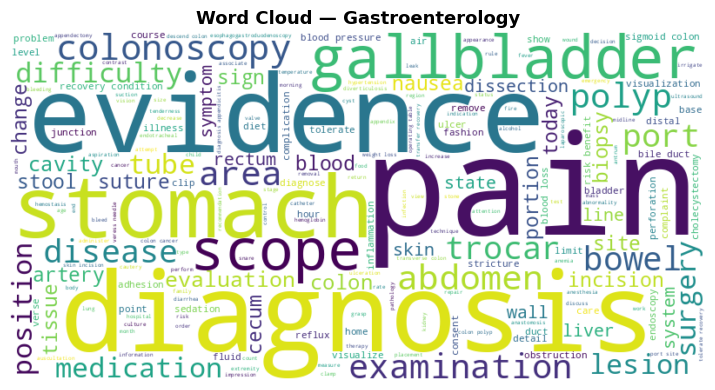

Skipping Word Cloud for 'Radiology ' due to no relevant words.


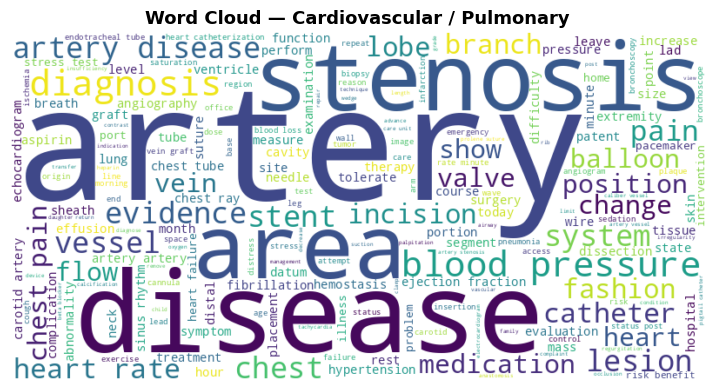

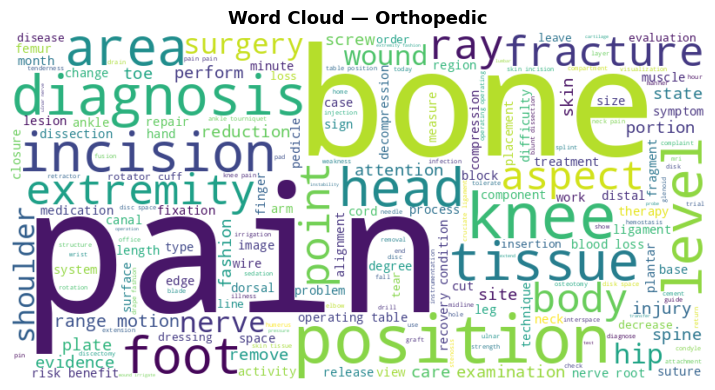

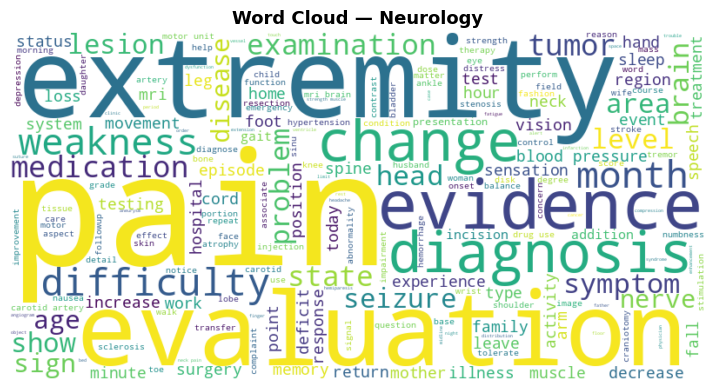

In [24]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def generate_filtered_wordcloud(specialty):
    subset = df[df["medical_specialty"] == specialty]
    text_words = [
        n for noun_list in subset["nouns"]
        for n in noun_list
        if n not in medical_stopwords and len(n) > 2
    ]
    text = " ".join(text_words)

    if not text.strip(): # Check if text is empty or only whitespace
        print(f"Skipping Word Cloud for '{specialty}' due to no relevant words.")
        return

    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.figure(figsize=(10, 4))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud — {specialty}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

for spec in SELECTED_SPECIALTIES:
    generate_filtered_wordcloud(spec)

# Phase 3: Negation Detection

In [25]:
negation_triggers = {"no", "not", "without", "deny", "denies", "denied"}
medical_ignore     = {"patient"}

def detect_negation(text):
    doc     = nlp(text)
    results = []
    for token in doc:
        if token.pos_ in ("NOUN", "PROPN") and token.text.lower() not in medical_ignore:
            is_negated = any(
                child.text.lower() in negation_triggers
                for child in token.head.children
            ) or any(
                token.dep_ in ("nsubj", "dobj", "attr")
                and token.head.text.lower() in negation_triggers
                for _ in [None]
            )
            results.append({
                "Entity": token.text,
                "Status": "Negated" if is_negated else "Present"
            })
    return results

# Demo
demo_sentences = [
    "Patient denies chest pain.",
    "No fever was noted during examination.",
    "The patient has no history of hypertension.",
    "Patient reports shortness of breath.",
    "There is no evidence of fracture.",
]
print("=== Negation Detection Demo ===")
for sent in demo_sentences:
    res = detect_negation(sent)
    print(f"\nSentence: \"{sent}\"")
    for r in res:
        icon = "✅ Present" if r["Status"] == "Present" else "❌ Negated"
        print(f"  Entity: '{r['Entity']}'  →  {icon}")

=== Negation Detection Demo ===

Sentence: "Patient denies chest pain."
  Entity: 'chest'  →  ✅ Present
  Entity: 'pain'  →  ❌ Negated

Sentence: "No fever was noted during examination."
  Entity: 'fever'  →  ✅ Present
  Entity: 'examination'  →  ✅ Present

Sentence: "The patient has no history of hypertension."
  Entity: 'history'  →  ✅ Present
  Entity: 'hypertension'  →  ✅ Present

Sentence: "Patient reports shortness of breath."
  Entity: 'shortness'  →  ✅ Present
  Entity: 'breath'  →  ✅ Present

Sentence: "There is no evidence of fracture."
  Entity: 'evidence'  →  ✅ Present
  Entity: 'fracture'  →  ✅ Present


In [54]:
sample_input = "Patient denies chest pain or any history of diabetes."
negation_output = detect_negation(sample_input)

print(f'Input Sentence: "{sample_input}"')
print("\nOutput Dictionary:")
import json
print(json.dumps(negation_output, indent=4))

Input Sentence: "Patient denies chest pain or any history of diabetes."

Output Dictionary:
[
    {
        "Entity": "chest",
        "Status": "Present"
    },
    {
        "Entity": "pain",
        "Status": "Negated"
    },
    {
        "Entity": "history",
        "Status": "Present"
    },
    {
        "Entity": "diabetes",
        "Status": "Present"
    }
]


In [53]:
from spacy import displacy

# Visualize the dependency tree for a sample clinical sentence
sample_text = "Patient denies any chest pain or shortness of breath."
doc = nlp(sample_text)

# Render the dependency tree
displacy.render(doc, style="dep", jupyter=True, options={"distance": 120})

In [26]:
df["negation_analysis"] = df["transcription"].apply(detect_negation)

# Show one row with a negated finding
for i, row in df.iterrows():
    if any(item["Status"] == "Negated" for item in row["negation_analysis"]):
        print("Specialty:", row["medical_specialty"])
        print("Text:", row["transcription"][:300])
        print("Negation:", row["negation_analysis"][:5])
        break

Specialty: Cardiovascular / Pulmonary
Text: 2-D M-MODE: , ,1.  Left atrial enlargement with left atrial diameter of 4.7 cm.,2.  Normal size right and left ventricle.,3.  Normal LV systolic function with left ventricular ejection fraction of 51%.,4.  Normal LV diastolic function.,5.  No pericardial effusion.,6.  Normal morphology of aortic val
Negation: [{'Entity': 'M', 'Status': 'Present'}, {'Entity': 'MODE', 'Status': 'Present'}, {'Entity': 'enlargement', 'Status': 'Present'}, {'Entity': 'diameter', 'Status': 'Present'}, {'Entity': 'cm', 'Status': 'Present'}]


# Phase 4: Specialty Classification

In [27]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import seaborn as sns

print("All classification imports successful.")

All classification imports successful.


Classification dataset shape: (1173, 10)

Class distribution:
medical_specialty
Cardiovascular / Pulmonary    371
Orthopedic                    355
Gastroenterology              224
Neurology                     223
Name: count, dtype: int64


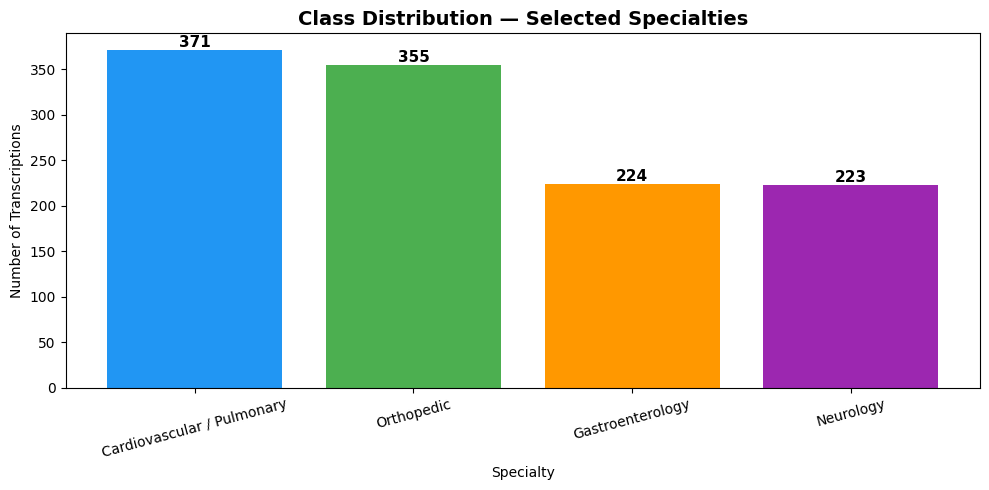


Imbalance ratio: 1.66x


In [28]:
# Prepare classification dataframe
df_clf = df[df["medical_specialty"].isin(SELECTED_SPECIALTIES)].copy()
df_clf = df_clf.dropna(subset=["clean_text"])
df_clf = df_clf[df_clf["clean_text"].str.strip() != ""].reset_index(drop=True)

print("Classification dataset shape:", df_clf.shape)
print("\nClass distribution:")
class_counts = df_clf["medical_specialty"].value_counts()
print(class_counts)

# Visualise class balance
plt.figure(figsize=(10, 5))
bars = plt.bar(class_counts.index, class_counts.values,
               color=["#2196F3", "#4CAF50", "#FF9800", "#9C27B0"])
plt.title("Class Distribution — Selected Specialties", fontsize=14, fontweight="bold")
plt.xlabel("Specialty")
plt.ylabel("Number of Transcriptions")
for bar, val in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             str(val), ha="center", fontsize=11, fontweight="bold")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

imbalance = class_counts.max() / class_counts.min()
print(f"\nImbalance ratio: {imbalance:.2f}x")

In [29]:
X = df_clf["clean_text"]
y = df_clf["medical_specialty"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {len(X_train)}  |  Test: {len(X_test)}")
print("\nTrain class distribution:")
print(y_train.value_counts())

Train: 938  |  Test: 235

Train class distribution:
medical_specialty
Cardiovascular / Pulmonary    297
Orthopedic                    284
Gastroenterology              179
Neurology                     178
Name: count, dtype: int64


In [30]:
#  Domain-specific stopwords — generic medical terms that appear in every
#  specialty and hurt discrimination.
#  max_features reduced to 10,000 to focus on discriminative terms and
#  cut noise from rare jargon appearing only once or twice.

DOMAIN_STOPWORDS = [
    "patient", "procedure", "history", "note", "report",
    "exam", "assessment", "plan", "result", "finding",
    "year", "day", "week", "time", "room", "place",
    "discharge", "admission", "review", "documentation",
    "follow", "study", "medication", "use", "dose",
]
# CONVERT TEXT TO NUMERICAL MATRIX
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10_000,
    min_df=3, #REMOVING RARE NOISE
    max_df=0.90, #REMOVING WORDS THAT APPREAR >90% OF DOCUMENT (EG:PATIENT)
    sublinear_tf=True, #LOG SCALING
    analyzer="word",
    token_pattern=r"\b[a-zA-Z][a-zA-Z]+\b",
    stop_words=DOMAIN_STOPWORDS,
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"TF-IDF train shape : {X_train_tfidf.shape}")
print(f"TF-IDF test  shape : {X_test_tfidf.shape}")
print(f"Vocabulary size    : {len(tfidf.vocabulary_):,}")

TF-IDF train shape : (938, 10000)
TF-IDF test  shape : (235, 10000)
Vocabulary size    : 10,000


In [33]:


from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        min_df=3, max_df=0.90, sublinear_tf=True,
        analyzer="word", token_pattern=r"\b[a-zA-Z][a-zA-Z]+\b",
        stop_words=DOMAIN_STOPWORDS
    )),
    ("clf", LogisticRegression(
        max_iter=1000, class_weight="balanced",
        solver="lbfgs", multi_class="multinomial", random_state=42
    ))
])

param_grid = {
    "tfidf__ngram_range" : [(1, 1), (1, 2)],
    "tfidf__max_features": [8000, 12000, 15000],
    "clf__C"             : [0.1, 1.0, 5.0, 10.0],
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    lr_pipeline, param_grid,
    cv=skf,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)   # fit on full dataset with CV

print("\n=== GridSearchCV Results ===")
print(f"Best Macro F1 (CV): {grid_search.best_score_:.4f}")
print(f"Best params       : {grid_search.best_params_}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits

=== GridSearchCV Results ===
Best Macro F1 (CV): 0.8953
Best params       : {'clf__C': 1.0, 'tfidf__max_features': 8000, 'tfidf__ngram_range': (1, 1)}


In [35]:
# Evaluate best GridSearch pipeline on the held-out test set
best_pipeline = grid_search.best_estimator_
y_pred_best   = best_pipeline.predict(X_test)

print("\n" + "="*58)
print(f"  BEST TUNED MODEL (GridSearch LR)")
print("="*58)
print(f"  Accuracy    : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"  Macro F1    : {f1_score(y_test, y_pred_best, average='macro'):.4f}")
print(f"  Weighted F1 : {f1_score(y_test, y_pred_best, average='weighted'):.4f}")
print("\n--- Detailed Classification Report ---")

# Get the actual unique classes present in the test set to resolve the mismatch
actual_classes_in_test = sorted(y_test.unique())

print(classification_report(y_test, y_pred_best, target_names=actual_classes_in_test))


  BEST TUNED MODEL (GridSearch LR)
  Accuracy    : 0.9489
  Macro F1    : 0.9475
  Weighted F1 : 0.9491

--- Detailed Classification Report ---
                            precision    recall  f1-score   support

Cardiovascular / Pulmonary       0.99      0.93      0.96        74
          Gastroenterology       0.94      0.98      0.96        45
                 Neurology       0.90      0.96      0.92        45
                Orthopedic       0.96      0.94      0.95        71

                  accuracy                           0.95       235
                 macro avg       0.94      0.95      0.95       235
              weighted avg       0.95      0.95      0.95       235



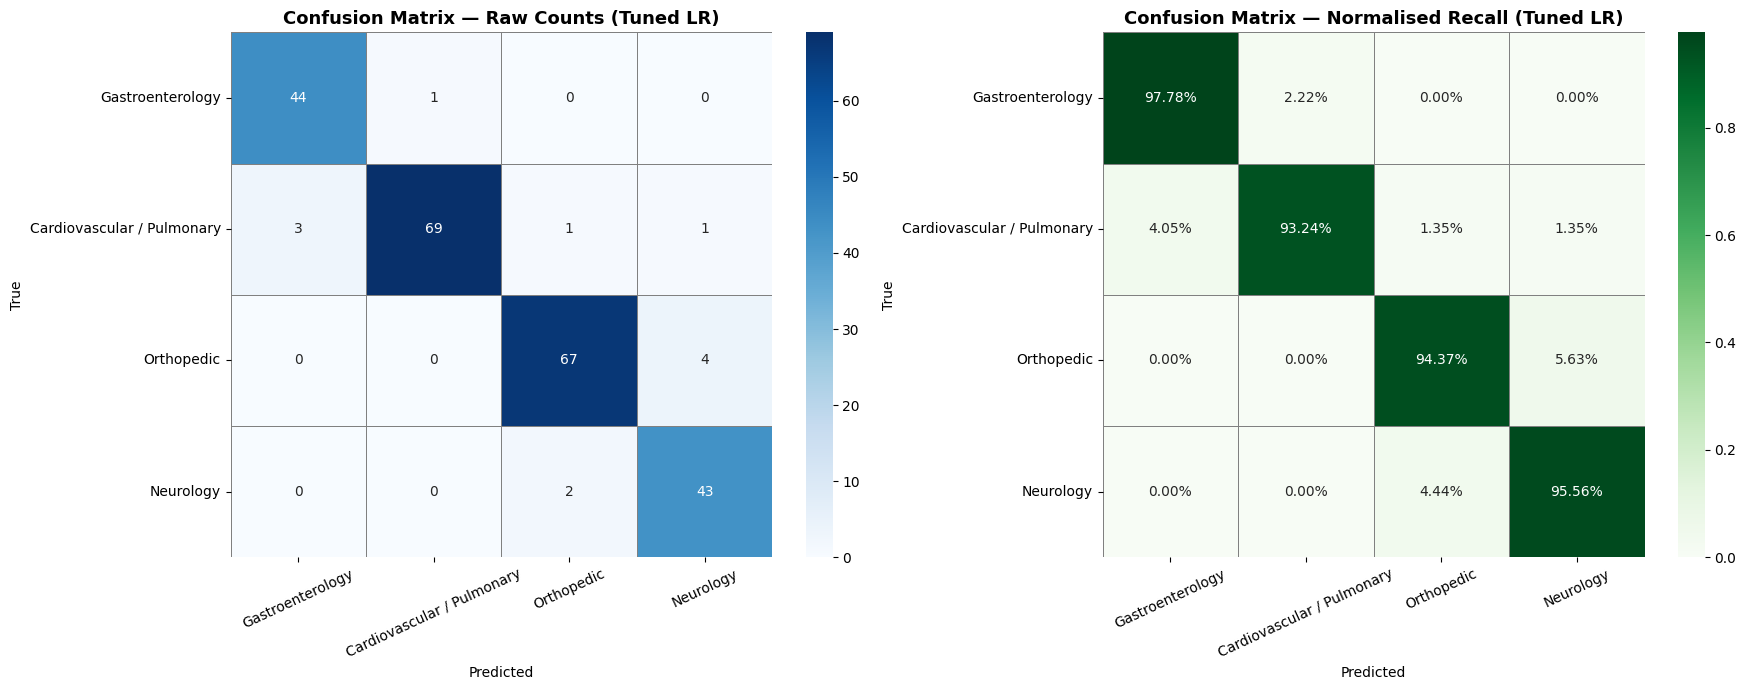

In [43]:
# Confusion matrix — raw counts + normalised recall
cm      = confusion_matrix(y_test, y_pred_best, labels=SELECTED_SPECIALTIES)
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=SELECTED_SPECIALTIES, yticklabels=SELECTED_SPECIALTIES,
            ax=axes[0], linewidths=0.5, linecolor="gray")
axes[0].set_title("Confusion Matrix — Raw Counts (Tuned LR)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].tick_params(axis="x", rotation=25)

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens",
            xticklabels=SELECTED_SPECIALTIES, yticklabels=SELECTED_SPECIALTIES,
            ax=axes[1], linewidths=0.5, linecolor="gray")
axes[1].set_title("Confusion Matrix — Normalised Recall (Tuned LR)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

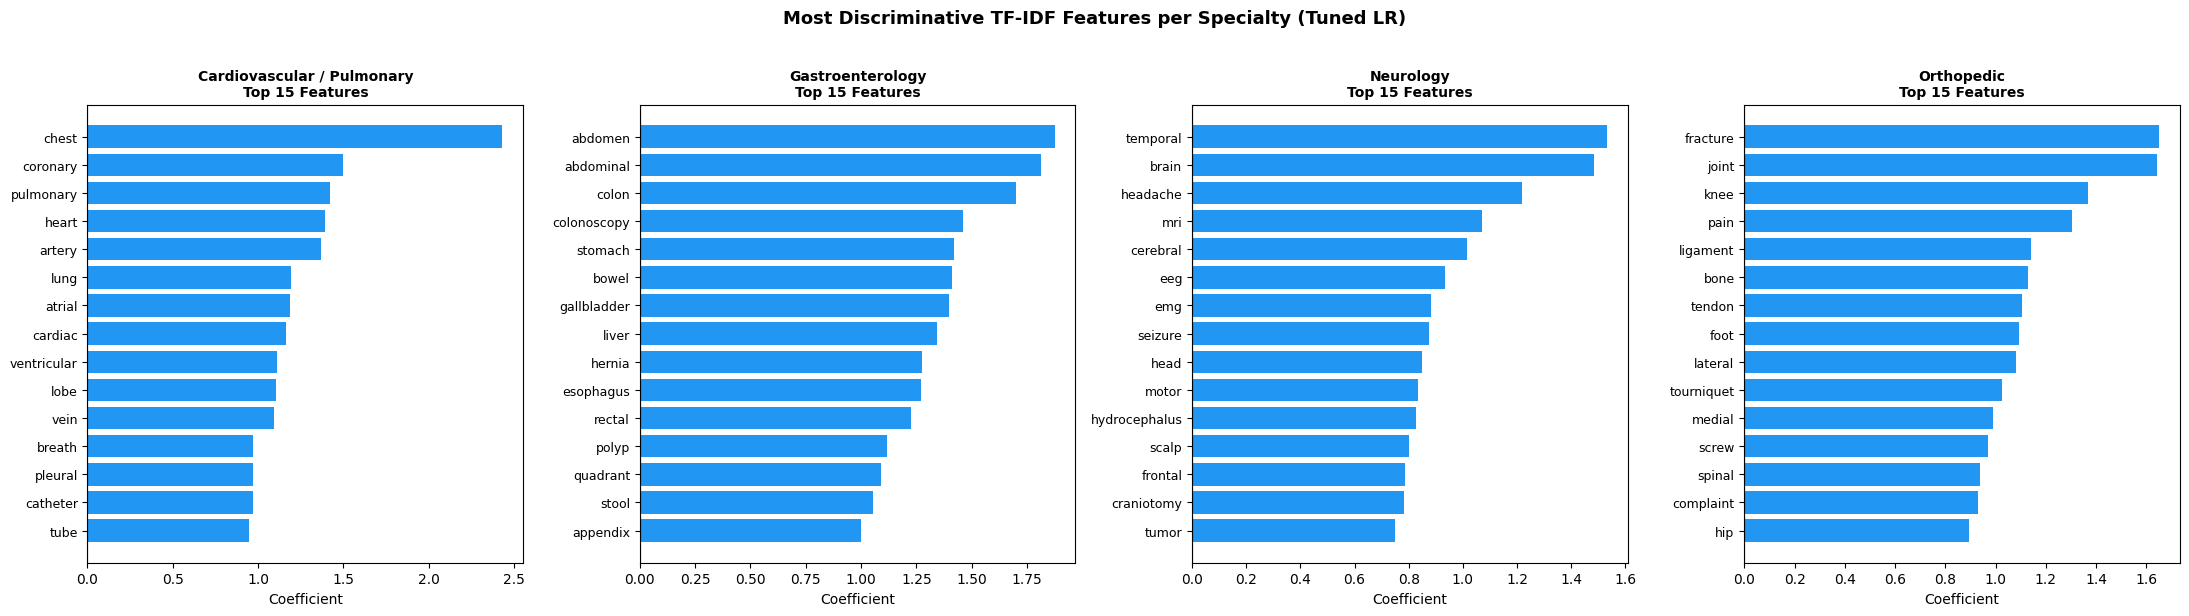

In [44]:
# Top discriminative features per class
best_tfidf = best_pipeline.named_steps["tfidf"]
best_clf_lr = best_pipeline.named_steps["clf"]
feature_names = np.array(best_tfidf.get_feature_names_out())
classes = best_clf_lr.classes_
coef    = best_clf_lr.coef_

fig, axes = plt.subplots(1, len(classes), figsize=(22, 6))
for i, (cls, ax) in enumerate(zip(classes, axes)):
    top_idx      = np.argsort(coef[i])[-15:][::-1]
    top_features = feature_names[top_idx]
    top_weights  = coef[i][top_idx]
    colors       = ["#2196F3" if w > 0 else "#E91E63" for w in top_weights]
    ax.barh(range(len(top_features)), top_weights[::-1], color=colors[::-1])
    ax.set_yticks(range(len(top_features)))
    ax.set_yticklabels(top_features[::-1], fontsize=9)
    ax.set_title(f"{cls}\nTop 15 Features", fontsize=10, fontweight="bold")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Coefficient")
plt.suptitle("Most Discriminative TF-IDF Features per Specialty (Tuned LR)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## Error Analysis: Misclassified Examples

In [45]:
# FIX 8: Qualitative error analysis — inspect 3–5 misclassified examples
# Helps distinguish vocabulary-overlap errors from truly ambiguous cases.

X_test_list = X_test.reset_index(drop=True)
y_test_list = y_test.reset_index(drop=True)
y_pred_list = pd.Series(y_pred_best, name="predicted")

errors = [
    (X_test_list.iloc[i], y_test_list.iloc[i], y_pred_list.iloc[i])
    for i in range(len(y_test_list))
    if y_test_list.iloc[i] != y_pred_list.iloc[i]
]

print(f"Total misclassifications: {len(errors)} / {len(y_test_list)}")
print("\n" + "="*70)
print("MISCLASSIFIED EXAMPLES (first 5)")
print("="*70)

for idx, (text, true_lbl, pred_lbl) in enumerate(errors[:5], 1):
    # Show raw transcription snippet from original df
    match = df_clf[df_clf["clean_text"] == text]
    snippet = match["transcription"].values[0][:350] if len(match) > 0 else text[:350]
    print(f"\n[Example {idx}]")
    print(f"  True label      : {true_lbl}")
    print(f"  Predicted label : {pred_lbl}")
    print(f"  Transcription   : {snippet}...")
    print("-"*70)

print("\nINSIGHT: Errors often occur when a specialty note uses generic")
print("procedural language that overlaps with another class's vocabulary.")

Total misclassifications: 12 / 235

MISCLASSIFIED EXAMPLES (first 5)

[Example 1]
  True label      : Cardiovascular / Pulmonary
  Predicted label : Gastroenterology
  Transcription   : OPERATION,1.  Ivor-Lewis esophagogastrectomy.,2.  Feeding jejunostomy.,3.  Placement of two right-sided #28-French chest tubes.,4.  Right thoracotomy.,ANESTHESIA:  ,General endotracheal anesthesia with a dual-lumen tube.,OPERATIVE PROCEDURE IN DETAIL: , After obtaining informed consent from the patient, including a thorough explanation of the risks...
----------------------------------------------------------------------

[Example 2]
  True label      : Cardiovascular / Pulmonary
  Predicted label : Gastroenterology
  Transcription   : PREOPERATIVE DIAGNOSIS: , Left adrenal mass, 5.5 cm.,POSTOPERATIVE DIAGNOSES:,1.  Left adrenal mass, 5.5 cm.,2.  Intraabdominal adhesions.,PROCEDURE PERFORMED:,1.  Laparoscopic lysis of adhesions.,2.  Laparoscopic left adrenalectomy.,ANESTHESIA: , General.,ESTIMATED BLOOD

In [46]:
# 5-Fold cross-validation on best pipeline for stable estimate
cv_scores = cross_val_score(
    best_pipeline, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_macro", n_jobs=-1
)
print(f"5-Fold CV Macro F1 — Tuned Logistic Regression")
print(f"  Fold scores : {cv_scores.round(4)}")
print(f"  Mean        : {cv_scores.mean():.4f}")
print(f"  Std Dev     : {cv_scores.std():.4f}")

5-Fold CV Macro F1 — Tuned Logistic Regression
  Fold scores : [0.8713 0.8783 0.9129 0.8916 0.9225]
  Mean        : 0.8953
  Std Dev     : 0.0197


## End-to-End Triage Demo

In [47]:
def triage_report(raw_text):
    cleaned   = preprocess_text(raw_text)
    predicted = best_pipeline.predict([cleaned])[0]
    print(f"\n{'='*55}")
    print(f"  TRIAGE RESULT: {predicted}")
    print(f"{'='*55}")
    print(f"  Input (first 200 chars): {raw_text[:200]}...")
    return predicted

test_cases = [
    "Patient presents with crushing chest pain radiating to left arm. EKG shows ST elevation. History of hypertension.",
    "Patient has right knee pain and swelling after fall. X-ray shows tibial plateau fracture.",
    "Patient complains of severe headache, photophobia, and neck stiffness. Lumbar puncture performed.",
    "Colonoscopy revealed polyps in the sigmoid colon. Biopsy sent to pathology. GI follow-up recommended.",
]
for tc in test_cases:
    triage_report(tc)


  TRIAGE RESULT: Cardiovascular / Pulmonary
  Input (first 200 chars): Patient presents with crushing chest pain radiating to left arm. EKG shows ST elevation. History of hypertension....

  TRIAGE RESULT: Orthopedic
  Input (first 200 chars): Patient has right knee pain and swelling after fall. X-ray shows tibial plateau fracture....

  TRIAGE RESULT: Neurology
  Input (first 200 chars): Patient complains of severe headache, photophobia, and neck stiffness. Lumbar puncture performed....

  TRIAGE RESULT: Gastroenterology
  Input (first 200 chars): Colonoscopy revealed polyps in the sigmoid colon. Biopsy sent to pathology. GI follow-up recommended....


In [48]:
# Final summary
print("\n" + "="*60)
print("   FINAL ACCURACY SUMMARY")
print("="*60)
report_dict = classification_report(
    y_test, y_pred_best, target_names=SELECTED_SPECIALTIES, output_dict=True
)
summary_df = pd.DataFrame(report_dict).T.loc[SELECTED_SPECIALTIES]
summary_df = summary_df[["precision", "recall", "f1-score", "support"]].round(3)
summary_df.columns = ["Precision", "Recall", "F1-Score", "Support"]

print(f"Best model   : Logistic Regression (GridSearchCV tuned)")
print(f"Accuracy     : {accuracy_score(y_test, y_pred_best):.2%}")
print(f"Macro F1     : {f1_score(y_test, y_pred_best, average='macro'):.2%}")
print(f"Weighted F1  : {f1_score(y_test, y_pred_best, average='weighted'):.2%}")
print("\nPer-Specialty Breakdown:")
print(summary_df.to_string())


   FINAL ACCURACY SUMMARY
Best model   : Logistic Regression (GridSearchCV tuned)
Accuracy     : 94.89%
Macro F1     : 94.75%
Weighted F1  : 94.91%

Per-Specialty Breakdown:
                            Precision  Recall  F1-Score  Support
Gastroenterology                0.986   0.932     0.958     74.0
Cardiovascular / Pulmonary      0.936   0.978     0.957     45.0
Orthopedic                      0.896   0.956     0.925     45.0
Neurology                       0.957   0.944     0.950     71.0
